[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QTL_AdversarialTransferLearning_Khatun2024.ipynb)

# Quantum transfer learning and its adversarial robustness: Khatun & Usman 2024, step by step

**Paper.** Amena Khatun and Muhammad Usman, *Quantum Transfer Learning with Adversarial Robustness for Classification of High-Resolution Image Datasets*, Advanced Quantum Technologies (Wiley), 2024, DOI [10.1002/qute.202400268](https://doi.org/10.1002/qute.202400268), preprint arXiv:2401.17009.

**What this notebook does.** It rebuilds the paper's "quantum transfer learning" (QTL) classifier: an ImageNet-pretrained, frozen **ResNet-18** turns each image into 512 numbers, a trainable layer squeezes them to **6 angles**, a **6-qubit variational circuit** (Hadamard + RY encoding, 6 layers of RX/RY/RZ rotations with CNOTs, Pauli-Z read-out) processes them and a last classical layer predicts the class. It then attacks the whole network with the **Fast Gradient Sign Method (FGSM)** and repeats the experiment after **adversarial training**. Everything is compared with (a) the same network with a classical head, and (b) the same networks trained **without transfer learning** (random ResNet-18, all layers trained).

**How to run.** Colab, CPU runtime, *Run all*. With `FAST_MODE = True` (the setting of the executed copy kept in the repository: reduced sample sizes, 64 x 64 images, short adversarial-training budgets) the numbers are noisy; that run took about 106 minutes of wall time on a laptop whose CPU was shared with a dozen other jobs, using one thread (an idle machine is several times faster). `FAST_MODE = False` follows the larger budgets written in the configuration cell (several hours on a CPU; it was **not** executed for the committed copy). The datasets are downloaded inside the notebook from public Hugging Face mirrors; no account or token is needed (an optional Hugging Face token is read only from the environment or Colab Secrets).

**What you get at the end.** The paper's Table I (clean accuracy of 4 methods on 2 datasets), Table II/IV (accuracy under FGSM, after adversarial training), the accuracy-versus-attack-strength curve of Fig. 6, a PGD stress test that the paper does not contain, and a per-claim verdict "reproduced / not reached / exceeded / cannot be checked".

**Important honesty note.** The paper runs on 224-pixel-class images with 50 training epochs on an HPC cluster. This notebook has to run on a shared laptop CPU, so images are shrunk to 64 x 64 pixels and the budgets are much smaller. Absolute numbers will therefore differ from the paper; the *comparisons* (quantum vs classical head, with vs without transfer learning, before vs after adversarial training) are what can be checked.

## The paper in one page

**Problem.** Quantum circuits have few qubits and are noisy, so they cannot take a 768 x 512 or 1024 x 1024 photograph directly. Transfer learning (TL) lets a big *classical* network trained on ImageNet do the heavy lifting and hands a very short feature vector to the quantum circuit. The paper asks three questions: (1) is QTL better than classical TL, (2) is TL needed at all, (3) is QTL vulnerable to adversarial examples and does adversarial training (AT) fix it?

**Model (Fig. 2, Sec. III).** Image -> ResNet-18 (frozen, ImageNet) -> 512 features -> fully connected layer with 6 outputs (the only trainable classical layer before the circuit) -> data encoding on 6 qubits (Hadamard, then RY) -> quantum variational circuit (RX, RY, RZ rotations and CNOT gates, "6 variational layers", weights initialised with spread 0.01) -> expectation values of 6 observables (Pauli Z) -> fully connected layer -> class. **Without TL** (Fig. 2d) all ResNet-18 layers are trained as well. Training: PennyLane + PyTorch, Adam, batch 16, learning rate 0.0004, constant for 25 epochs then linear decay to 0 over 25 more, cross-entropy loss.

**Attack (Sec. III-D).** White-box, non-targeted FGSM, `x_adv = x + eps * sign(grad_x loss)` with `eps` in {0.1, 0.2, 0.3} (Ants & Bees) or {0.1, 0.3, 1.0} (Road Sign, CIFAR-10). **Adversarial training (Sec. III-E):** the training set contains the original images and their adversarial versions; the threat model is the L-infinity ball of radius `eps`.

**Data.** Ants & Bees (the PyTorch "hymenoptera" set: ~245 training and 153 validation photographs), CIFAR-10 (50,000 + 10,000 images of 32 x 32), Road Sign Detection (877 images, 4 classes, 80/20 split).

**Claims to check.** Table I (clean accuracy), Table II (Ants & Bees), Table III (Road Sign), Table IV (CIFAR-10), Fig. 6, and the sentences "QTL outperforms classical TL by 1.4 / 3.7 / 2.2 points", "TL is essential (QNN without TL loses 30-46 points)", "undefended QTL is as vulnerable as classical TL", "AT raises accuracy under attack by 18-20 points and QTL-AT beats every other method".

| Paper's result | Value |
|---|---|
| Table I, Ants & Bees: classical TL / classical w/o TL / quantum TL / quantum w/o TL | 94.7 / 62.75 / 96.1 / 65.36 % |
| Table I, CIFAR-10: same four methods | 92.1 / 72.9 / 95.8 / 51.7 % |
| Table II, quantum TL, eps 0.1: clean / under attack / AT model: clean / AT model: under attack | 96.10 / 53.85 / 94.76 / 71.87 % |
| Table IV, quantum TL on CIFAR-10, eps 0.1: under attack / after AT | 50.9 / 86.6 % |

### What follows the paper and what had to be chosen

The paper is short on implementation details. Every row marked *chosen* is a `# CHOICE:` comment in the code.

| Item | Paper | This notebook |
|---|---|---|
| Pretrained network | ResNet-18, ImageNet | same (torchvision `IMAGENET1K_V1`), frozen, BatchNorm in eval mode |
| Image size | 768x512 (Ants & Bees), 32x32 (CIFAR-10) | **chosen:** centre-crop to a square and shrink to **64 x 64** (CIFAR-10 is enlarged 32 -> 64); CPU budget of a shared laptop |
| Ants & Bees split | 120 + 75 images per class (text), tutorial set in practice | the 245 training / 153 validation images of the public mirror; the validation folder is used as the **test set**, nothing is tuned on it |
| CIFAR-10 size | 50,000 train / 10,000 test | **chosen:** class-balanced random subset (sizes in the configuration cell) |
| Road Sign Detection | 877 images, 4 classes | **cannot be reproduced:** the Kaggle set is an object-detection set with no image-level label and no Hugging Face mirror with those 4 classes; Table III is reported as "cannot be checked" |
| Qubits / depth | 6 qubits, 6 variational layers | same |
| Encoding | Hadamard, then RY of the 6 features | same; **chosen:** the angle is `tanh(Wf+b) * pi/2` so it is bounded (Eq. 2 only says `RY(2x)`) |
| Variational block | RX, RY, RZ per qubit and CNOTs | same; **chosen:** order RX -> RY -> RZ, CNOT ring `i -> i+1 (mod 6)` after every rotation block |
| Weight initialisation | random with spread 0.01 | `0.01 * N(0, 1)` |
| Read-out | 6 observables | Pauli-Z expectation on every qubit, then `Linear(6 -> classes)` |
| Optimiser | Adam, lr 4e-4, batch 16, 50 epochs (25 constant + 25 linear decay) | same schedule (shorter in `FAST_MODE`); the extra "x0.1 every 10 epochs" sentence of the paper contradicts the linear decay and is not used |
| Classical TL baseline | "classical TL" (ResNet-18 + new classifier) | `Linear(512 -> classes)` on the same frozen features; **extra:** a classical head with the same 6-unit bottleneck, to isolate the circuit |
| Without TL | "entire architecture fine-tuned from scratch" | **chosen:** ResNet-18 with *random* weights, all layers trained (a pretrained start would not give 62-65 %) |
| FGSM strength | 0.1 / 0.2 / 0.3 | applied to the **ImageNet-normalised input tensor** (unit: one standardised pixel value; 0.1 is about 0.023 on the 0-1 pixel scale); the paper does not state the unit |
| Adversarial training | clean + adversarial images, eps as in the attack | each mini-batch is doubled with its FGSM version generated against the *current* model; **chosen:** warm start from the clean model and a few epochs (budget in the configuration cell) |
| Seeds | not stated | clean models: several seeds (`SEEDS`); adversarial training: first seed only (cost) |
| Extra beyond the paper | none | PGD (white-box, random start) as a stronger attack on the TL models |

In [1]:
# Installs (tested versions). Colab already ships torch, torchvision, numpy, pandas, scikit-learn, matplotlib.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    try:
        import pennylane, torch, torchvision, huggingface_hub, pyarrow, sklearn  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow", "pillow"])
    print("Installed pennylane 0.45.1. If Colab asks you to restart the session, do so and press Run all again.")
else:
    print("All dependencies are already present; nothing was installed.")

All dependencies are already present; nothing was installed.


In [2]:
# ===================== CONFIGURATION: every tunable constant lives here =====================
SEED = 42
FAST_MODE = True              # True: reduced budgets (the executed copy); False: the larger budgets below (several hours on a CPU, not executed here)
DATA_DIR = "data"             # downloads and caches go here (never inside a git repo)
IBM_TOKEN = ""                # not used: the 6-qubit circuit runs on an exact classical simulator
N_THREADS = 1                 # CHOICE: one torch thread; many threads thrash on a shared CPU (Colab: 2 also works)

# --- data (CHOICE: reduced resolution and subset sizes, see the table above)
HF_ANTS = "ggsmith/Hymenoptera"          # public mirror of the PyTorch hymenoptera set (ants vs bees)
HF_C10 = "uoft-cs/cifar10"               # public CIFAR-10 parquet files
C10_CACHE_PER_CLASS = (60, 50)           # the cached CIFAR-10 pool (train, test images per class); the runs below use the first few of each class
IMG_SIZE = 64                            # both datasets are shown to the network at 64 x 64
EPS_ANTS = [0.1, 0.2, 0.3]               # FGSM strengths of Table II (units: ImageNet-normalised input tensor)
EPS_C10 = [0.1, 0.3, 1.0]                # FGSM strengths of Table IV

# --- the quantum layer (paper: 6 qubits, 6 variational layers, weight spread 0.01)
N_QUBITS, N_LAYERS, Q_INIT_SPREAD = 6, 6, 0.01

# --- training (paper: Adam, lr 4e-4, batch 16, 50 epochs = 25 constant + 25 linear decay)
BATCH, LR = 16, 4e-4

if FAST_MODE:
    SEEDS = [42, 43, 44]                               # clean TL heads: three seeds (adversarial training and no-TL networks: first seed)
    C10_TRAIN_PER_CLASS, C10_TEST_PER_CLASS = 40, 30   # 400 train / 300 test CIFAR-10 images
    EPOCHS_HEAD = 50                                   # the paper's schedule for the heads on cached ResNet features (cheap)
    EVAL_N = {"ants_bees": 100, "cifar10": 100}        # test images attacked per evaluation
    AT_EPOCHS = {"ants_bees": 2, "cifar10": 1}         # adversarial-training epochs (TL models, warm start)
    SCRATCH_EPOCHS = {"ants_bees": 4, "cifar10": 2}    # epochs for the networks WITHOUT transfer learning
    SCRATCH_AT_EPOCHS = 1
    SCRATCH_AT_EPS = [0.1]                             # strengths for adversarial training without TL
    EXTRA_GRID = False                                 # extra attack strengths for the Fig. 6 curve
    PGD_STEPS, PGD_N = 3, 40
else:
    SEEDS = [42, 43, 44]
    C10_TRAIN_PER_CLASS, C10_TEST_PER_CLASS = 60, 50   # 600 train / 500 test CIFAR-10 images
    EPOCHS_HEAD = 50
    EVAL_N = {"ants_bees": 153, "cifar10": 200}
    AT_EPOCHS = {"ants_bees": 4, "cifar10": 2}
    SCRATCH_EPOCHS = {"ants_bees": 15, "cifar10": 4}
    SCRATCH_AT_EPOCHS = 2
    SCRATCH_AT_EPS = EPS_ANTS
    EXTRA_GRID = True
    PGD_STEPS, PGD_N = 10, 100
print(f"FAST_MODE={FAST_MODE}  seeds={SEEDS}  head epochs={EPOCHS_HEAD}  AT epochs={AT_EPOCHS}  scratch epochs={SCRATCH_EPOCHS}")

FAST_MODE=True  seeds=[42, 43, 44]  head epochs=50  AT epochs={'ants_bees': 2, 'cifar10': 1}  scratch epochs={'ants_bees': 4, 'cifar10': 2}


In [3]:
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
import io, sys, time, json, copy, glob, math, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import pennylane as qml
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
warnings.filterwarnings("ignore")

# Hugging Face token: only from the environment or Colab Secrets (both datasets below are public, so None works).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)
os.environ.setdefault("TORCH_HOME", os.path.join(os.path.abspath(DATA_DIR), "torch_home"))
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__,
      "| numpy", np.__version__, "| HF token present:", HF_TOKEN is not None)

torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | HF token present: True


## 1. Data: two public image sets, shrunk to 64 x 64

* **Ants & Bees** (`ggsmith/Hymenoptera`, MIT licence): the PyTorch tutorial's hymenoptera photographs, `train/` (ants and bees) and `val/`. The validation folder plays the role of the **test set**; no model selection uses it. Photographs are centre-cropped to a square and shrunk to `IMG_SIZE`.
* **CIFAR-10** (`uoft-cs/cifar10`): a class-balanced random subset of the official train and test splits, enlarged from 32 x 32 to `IMG_SIZE` with bilinear interpolation. The big training parquet is deleted after the subset has been cached.
* **Road Sign Detection** (third dataset of the paper): not reproducible, see the table above. It is reported as *cannot be checked*; no other road-sign set is substituted.

Both datasets are cached as small `.npz` files in `DATA_DIR`.

In [4]:
AB_CLASSES = ["ant", "bee"]
C10_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def _square(im, size):
    # CHOICE: centre-crop to a square (keeps the aspect ratio of the objects), then shrink
    w, h = im.size; s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
    return np.asarray(im.resize((size, size), Image.BILINEAR))

def build_ants():
    from huggingface_hub import snapshot_download
    root = snapshot_download(HF_ANTS, repo_type="dataset", local_dir=f"{DATA_DIR}/hymenoptera", token=HF_TOKEN,
                             allow_patterns=["train/*/*.jpg", "train/*/*.jpeg", "val/*/*.jpg", "val/*/*.jpeg"])
    out = {}
    for split in ("train", "val"):
        X, y, names = [], [], []
        for c, cname in enumerate(["ants", "bees"]):
            for p in sorted(glob.glob(f"{root}/{split}/{cname}/*")):
                X.append(_square(Image.open(p).convert("RGB"), IMG_SIZE)); y.append(c); names.append(os.path.basename(p))
        out[split] = (np.stack(X), np.array(y), np.array(names))
    return out

def build_c10():
    import pyarrow.parquet as pq
    from huggingface_hub import hf_hub_download
    out = {}
    for split, per in (("train", C10_CACHE_PER_CLASS[0]), ("test", C10_CACHE_PER_CLASS[1])):
        p = hf_hub_download(HF_C10, f"plain_text/{split}-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN,
                            local_dir=f"{DATA_DIR}/cifar10")
        lab = np.array(pq.read_table(p, columns=["label"]).column("label").to_pylist())
        draw = np.random.default_rng(SEED)               # same subset for every run with this SEED
        pick = np.sort(np.concatenate([draw.choice(np.where(lab == c)[0], per, replace=False) for c in range(10)]))
        want, X = set(pick.tolist()), {}
        base = 0
        with pq.ParquetFile(p) as pf:                    # read row group by row group: small memory footprint
            for g in range(pf.num_row_groups):
                tab = pf.read_row_group(g, columns=["img"]).column("img")
                for j in range(len(tab)):
                    if base + j in want:
                        X[base + j] = _square(Image.open(io.BytesIO(tab[j].as_py()["bytes"])).convert("RGB"), IMG_SIZE)
                base += len(tab)
        out[split] = (np.stack([X[i] for i in pick]), lab[pick])
        if os.path.getsize(p) > 50e6:
            os.remove(p)                                 # do not keep the 120 MB training parquet
    return out

CACHE_AB = f"{DATA_DIR}/antsbees_{IMG_SIZE}px.npz"
if os.path.exists(CACHE_AB):
    d = np.load(CACHE_AB, allow_pickle=True)
    ab = {"train": (d["Xtr"], d["ytr"], d["ntr"]), "val": (d["Xte"], d["yte"], d["nte"])}
else:
    ab = build_ants()
    np.savez_compressed(CACHE_AB, Xtr=ab["train"][0], ytr=ab["train"][1], ntr=ab["train"][2],
                        Xte=ab["val"][0], yte=ab["val"][1], nte=ab["val"][2])

CACHE_C10 = f"{DATA_DIR}/cifar10_{IMG_SIZE}px_{C10_CACHE_PER_CLASS[0]}_{C10_CACHE_PER_CLASS[1]}_seed{SEED}.npz"
if os.path.exists(CACHE_C10):
    d = np.load(CACHE_C10); c10 = {"train": (d["Xtr"], d["ytr"]), "test": (d["Xte"], d["yte"])}
else:
    c10 = build_c10()
    np.savez_compressed(CACHE_C10, Xtr=c10["train"][0], ytr=c10["train"][1], Xte=c10["test"][0], yte=c10["test"][1])

def take_per_class(X, y, n):
    idx = np.concatenate([np.where(y == c)[0][:n] for c in range(10)])
    return X[idx], y[idx]
c10 = {"train": take_per_class(*c10["train"], C10_TRAIN_PER_CLASS), "test": take_per_class(*c10["test"], C10_TEST_PER_CLASS)}

DATA = {
    "ants_bees": dict(title="Ants & Bees", classes=AB_CLASSES, n_cls=2, eps=EPS_ANTS,
                      Xtr=ab["train"][0], ytr=ab["train"][1], Xte=ab["val"][0], yte=ab["val"][1]),
    "cifar10":   dict(title="CIFAR-10", classes=C10_CLASSES, n_cls=10, eps=EPS_C10,
                      Xtr=c10["train"][0], ytr=c10["train"][1], Xte=c10["test"][0], yte=c10["test"][1]),
}
for k, d in DATA.items():
    print(f"{d['title']:12s} train {d['Xtr'].shape} test {d['Xte'].shape}  classes {d['n_cls']}  "
          f"train counts {np.bincount(d['ytr']).tolist()}  test counts {np.bincount(d['yte']).tolist()}")

Ants & Bees  train (245, 64, 64, 3) test (153, 64, 64, 3)  classes 2  train counts [124, 121]  test counts [70, 83]
CIFAR-10     train (400, 64, 64, 3) test (300, 64, 64, 3)  classes 10  train counts [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]  test counts [30, 30, 30, 30, 30, 30, 30, 30, 30, 30]


## 2. The classical half: a frozen ImageNet ResNet-18

Images enter the network as **ImageNet-normalised tensors** (`(pixel/255 - mean) / std`). The ResNet-18 is cut after its global average pooling, so each image becomes a vector of 512 numbers (the 512 channels of the last stage). With transfer learning (TL) the ResNet is **frozen** (weights and BatchNorm statistics never change) and the 512-vectors of all training and test images are computed once and cached; without TL the same architecture starts from *random* weights and is trained end to end (later sections).

`LO` and `HI` are the smallest and largest values a valid image can have in normalised space; adversarial images are clipped to them so every attacked image is still a legal picture.

In [5]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
LO, HI = (0 - MEAN) / STD, (1 - MEAN) / STD           # valid range of a normalised pixel, per channel

def to_norm(Xu8):
    """uint8 NHWC array -> ImageNet-normalised float NCHW tensor"""
    t = torch.from_numpy(np.ascontiguousarray(Xu8)).permute(0, 3, 1, 2).float() / 255.0
    return (t - MEAN) / STD

def make_backbone(pretrained):
    """ResNet-18 up to the global average pool (512-d output). pretrained=True: ImageNet weights, frozen, eval mode."""
    w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = torchvision.models.resnet18(weights=w, progress=False)
    m.fc = nn.Identity()
    if pretrained:
        m.eval()
        for p in m.parameters():
            p.requires_grad_(False)
    return m

@torch.no_grad()
def extract(bb, Xu8, bs=64):
    bb.eval()
    return torch.cat([bb(to_norm(Xu8[s:s + bs])) for s in range(0, len(Xu8), bs)])

bb_tl = make_backbone(True)                            # the one frozen ImageNet ResNet-18 used by every TL model
t0 = time.time()
for k, d in DATA.items():
    d["Ftr"], d["Fte"] = extract(bb_tl, d["Xtr"]), extract(bb_tl, d["Xte"])
    d["ytr_t"], d["yte_t"] = torch.from_numpy(d["ytr"]).long(), torch.from_numpy(d["yte"]).long()
    print(f"{d['title']:12s} features train {tuple(d['Ftr'].shape)} test {tuple(d['Fte'].shape)}")
print(f"frozen-backbone features computed in {time.time() - t0:.0f}s")
print("pixel range in normalised space, per channel: LO =", LO.flatten().numpy().round(2), " HI =", HI.flatten().numpy().round(2),
      "| eps=0.1 in this space is about", round(0.1 * float(STD.mean()), 3), "on the 0-1 pixel scale")

Ants & Bees  features train (245, 512) test (153, 512)


CIFAR-10     features train (400, 512) test (300, 512)
frozen-backbone features computed in 48s
pixel range in normalised space, per channel: LO = [-2.12 -2.04 -1.8 ]  HI = [2.25 2.43 2.64] | eps=0.1 in this space is about 0.023 on the 0-1 pixel scale


## Dataset Exploration and Visualisation

What the data look like before any model sees them. For **each dataset** the first cell prints the shape, the feature names and the original label values with class counts, plots the real class distribution (train and test) and shows real images. The second cell draws 2-D scatter plots of the **real images coloured by their ground-truth class**: PCA of the raw pixels, PCA of the frozen ResNet-18 features (both fitted on the training split only) and the same feature coordinates scaled to [0, pi] the way an angle encoding would see them (test points are clipped to the training range). Both datasets are multi-class or binary exactly as in the paper (ants/bees, ten CIFAR-10 classes).

Ants & Bees: images (64, 64, 3) (H, W, RGB) uint8, train 245, test 153
raw pixel features: 12288 | network features: 512 channels 'resnet18.layer4[0..511]' after global average pooling
original label values -> class names, counts:
 label class  train  test
     0   ant    124    70
     1   bee    121    83


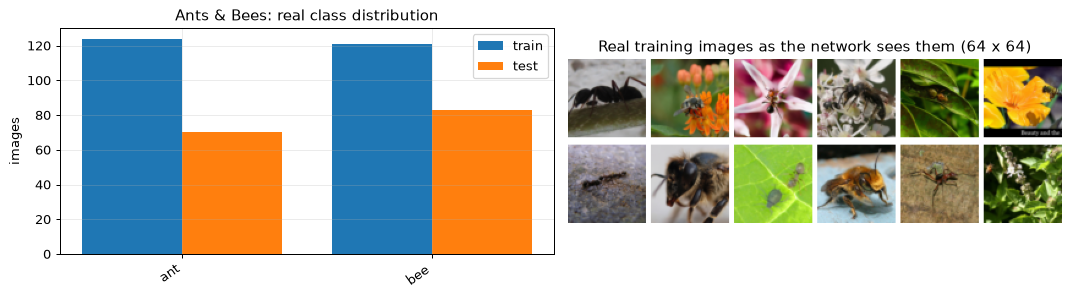

CIFAR-10: images (64, 64, 3) (H, W, RGB) uint8, train 400, test 300
raw pixel features: 12288 | network features: 512 channels 'resnet18.layer4[0..511]' after global average pooling
original label values -> class names, counts:
 label      class  train  test
     0   airplane     40    30
     1 automobile     40    30
     2       bird     40    30
     3        cat     40    30
     4       deer     40    30
     5        dog     40    30
     6       frog     40    30
     7      horse     40    30
     8       ship     40    30
     9      truck     40    30


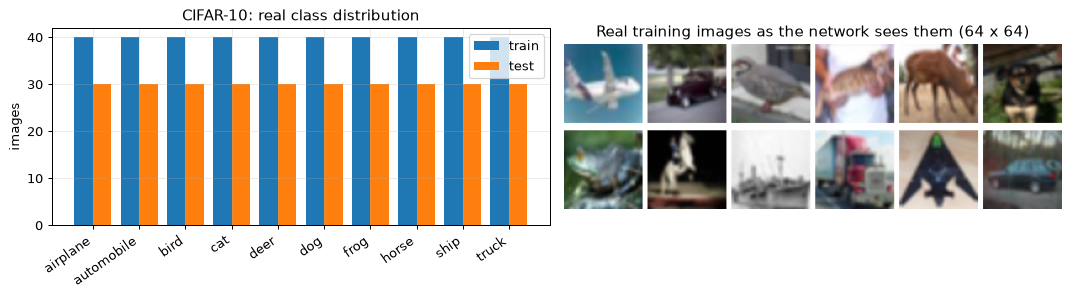

In [6]:
for key, d in DATA.items():
    print("=" * 100)
    print(f"{d['title']}: images {d['Xtr'].shape[1:]} (H, W, RGB) uint8, train {len(d['ytr'])}, test {len(d['yte'])}")
    print("raw pixel features:", int(np.prod(d['Xtr'].shape[1:])), "| network features: 512 channels 'resnet18.layer4[0..511]' after global average pooling")
    print("original label values -> class names, counts:")
    print(pd.DataFrame({"label": range(d["n_cls"]), "class": d["classes"],
                        "train": np.bincount(d["ytr"], minlength=d["n_cls"]), "test": np.bincount(d["yte"], minlength=d["n_cls"])}).to_string(index=False))

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
    xs, w_ = np.arange(d["n_cls"]), 0.4
    ax[0].bar(xs - w_ / 2, np.bincount(d["ytr"], minlength=d["n_cls"]), w_, label="train")
    ax[0].bar(xs + w_ / 2, np.bincount(d["yte"], minlength=d["n_cls"]), w_, label="test")
    ax[0].set_xticks(xs); ax[0].set_xticklabels(d["classes"], rotation=35, ha="right"); ax[0].legend()
    ax[0].set_title(f"{d['title']}: real class distribution"); ax[0].set_ylabel("images")
    rr = np.random.default_rng(SEED)
    ncol = 6
    grid = np.ones((2 * IMG_SIZE + 6, ncol * IMG_SIZE + (ncol - 1) * 4, 3), np.uint8) * 255
    for r_ in range(2):
        for c_ in range(ncol):
            cls = (r_ * ncol + c_) % d["n_cls"] if d["n_cls"] > 2 else c_ % 2
            i = int(rr.choice(np.where(d["ytr"] == cls)[0]))
            grid[r_ * (IMG_SIZE + 6): r_ * (IMG_SIZE + 6) + IMG_SIZE, c_ * (IMG_SIZE + 4): c_ * (IMG_SIZE + 4) + IMG_SIZE] = d["Xtr"][i]
    ax[1].imshow(grid); ax[1].axis("off"); ax[1].set_title("Real training images as the network sees them (64 x 64)")
    plt.tight_layout(); plt.show()

### 2-D scatter of the real observations (ground-truth colours)

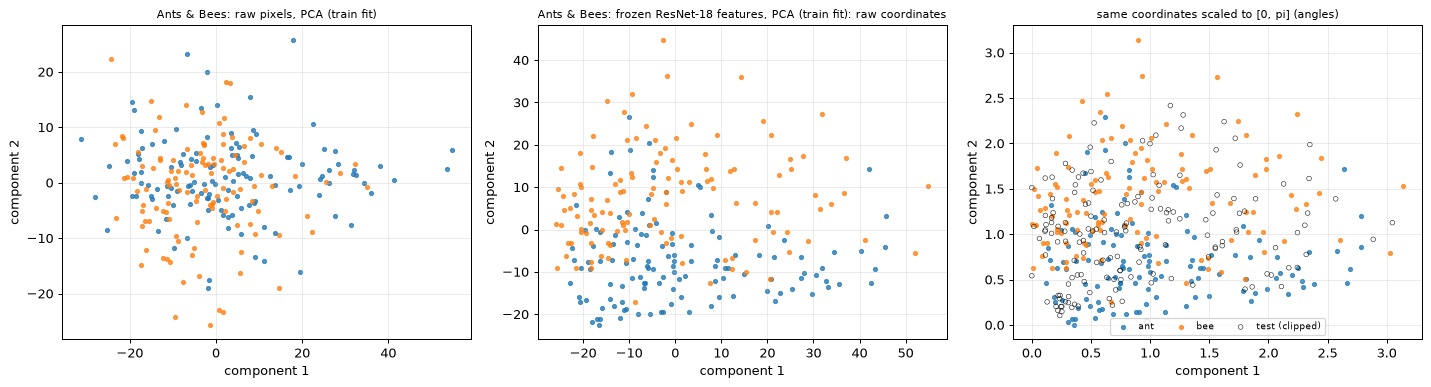

Ants & Bees: explained variance of the 2 feature components [0.15  0.076]; the classes separate far better in ResNet-feature space than in pixel space - the reason transfer learning helps.


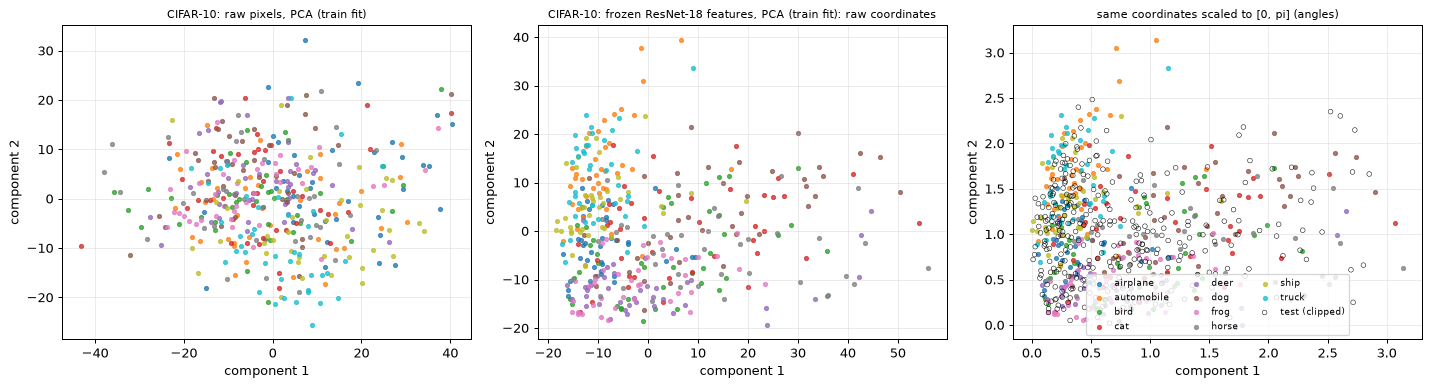

CIFAR-10: explained variance of the 2 feature components [0.129 0.068]; the classes separate far better in ResNet-feature space than in pixel space - the reason transfer learning helps.


In [7]:
def scatter(ax, Z, y, classes, title):
    cm = plt.cm.tab10
    for c in range(len(classes)):
        m = y == c
        ax.scatter(Z[m, 0], Z[m, 1], s=10, color=cm(c), label=classes[c], alpha=0.75)
    ax.set_title(title, fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")

for key, d in DATA.items():
    px_tr = d["Xtr"].reshape(len(d["ytr"]), -1).astype(np.float32) / 255
    pca_px = PCA(n_components=2, random_state=SEED).fit(px_tr)                    # fitted on the training split only
    Zpx = pca_px.transform(px_tr)
    Ftr_np, Fte_np = d["Ftr"].numpy(), d["Fte"].numpy()
    pca_ft = PCA(n_components=2, random_state=SEED).fit(Ftr_np)
    Zft_tr, Zft_te = pca_ft.transform(Ftr_np), pca_ft.transform(Fte_np)
    mm = MinMaxScaler((0, np.pi)).fit(Zft_tr)
    A_tr, A_te = mm.transform(Zft_tr), np.clip(mm.transform(Zft_te), 0, np.pi)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    scatter(ax[0], Zpx, d["ytr"], d["classes"], f"{d['title']}: raw pixels, PCA (train fit)")
    scatter(ax[1], Zft_tr, d["ytr"], d["classes"], f"{d['title']}: frozen ResNet-18 features, PCA (train fit): raw coordinates")
    scatter(ax[2], A_tr, d["ytr"], d["classes"], "same coordinates scaled to [0, pi] (angles)")
    ax[2].scatter(A_te[:, 0], A_te[:, 1], s=14, facecolors="none", edgecolors="k", linewidths=0.4, label="test (clipped)")
    ax[2].legend(fontsize=7, ncol=3, loc="lower center")
    plt.tight_layout(); plt.show()
    print(f"{d['title']}: explained variance of the 2 feature components {pca_ft.explained_variance_ratio_.round(3)}; "
          f"the classes separate far better in ResNet-feature space than in pixel space - the reason transfer learning helps.")

## Quantum Circuit Architecture

The quantum model of the paper is the 6-qubit variational circuit between the two fully connected layers (Fig. 2b). The cell below defines it as a PennyLane `QNode` and **draws exactly that QNode** with `qml.draw_mpl`:

* **Encoding**: a Hadamard on every qubit (superposition), then `RY(q_i)` where `q = tanh(W f + b) * pi/2` are the 6 angles produced by the classical layer in front of the circuit.
* **Quantum variational circuit**: `N_LAYERS = 6` layers; each layer applies `RX`, `RY`, `RZ` on every qubit (the paper's alpha, beta, gamma angles) followed by a ring of CNOT gates.
* **Measurement**: the Pauli-Z expectation value of every qubit, a vector in [-1, 1]^6 that goes to the final classical layer.

*Assumptions where the paper is silent:* rotation order RX -> RY -> RZ, CNOT ring `i -> i+1 (mod 6)` after every rotation block (the figure shows one CNOT column per block, its wiring is not printed), the `tanh * pi/2` bounding of the encoding angle (Eq. 2 writes `RY(2x)`), the read-out gate Pauli-Z, and `N_LAYERS = 6` taken from the "depth of the quantum circuit" sentence of Sec. IV (Fig. 2b draws two blocks). One architecture is trained, so there is one drawing. Training uses an exact torch twin of this QNode (section 4b), and a cell **asserts** that the twin equals the QNode in values and in gradients.

Matplotlib is building the font cache; this may take a moment.


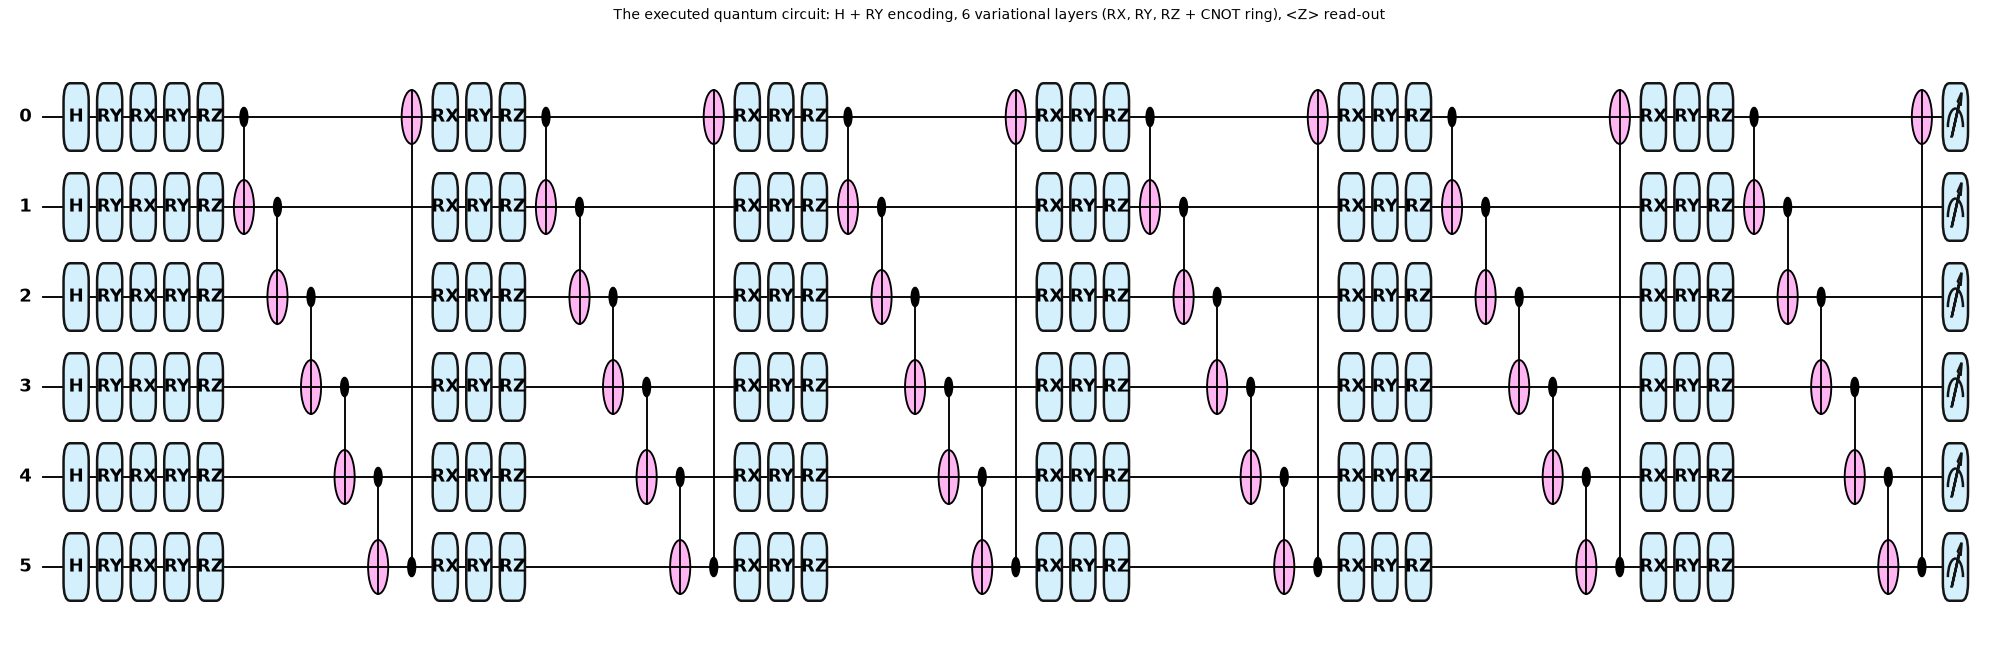

qubits: 6 | circuit depth: 56 | gates: 156 | trainable circuit parameters: 108 (= 6 layers x 6 qubits x 3 angles) | data-encoding angles per image: 6
assumptions where the paper is silent: rotation order RX-RY-RZ, CNOT ring after each block, tanh*pi/2 bounded encoding angle, <Z> read-out, 6 layers


In [8]:
# The variational quantum circuit of the paper, written as the PennyLane QNode that defines it.
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def vqc_qnode(x, w):
    """x: (..., N_QUBITS) encoding angles in [-pi/2, pi/2]; w: (N_LAYERS, N_QUBITS, 3) trainable angles (alpha, beta, gamma)."""
    for i in range(N_QUBITS):                        # encoding: Hadamard (superposition), then RY(feature)
        qml.Hadamard(wires=i)
        qml.RY(x[..., i], wires=i)
    for l in range(N_LAYERS):                        # variational layers: RX, RY, RZ on every qubit + CNOT ring
        for i in range(N_QUBITS):
            qml.RX(w[l, i, 0], wires=i)              # CHOICE: order RX -> RY -> RZ
            qml.RY(w[l, i, 1], wires=i)
            qml.RZ(w[l, i, 2], wires=i)
        for i in range(N_QUBITS):                    # CHOICE: CNOT ring i -> i+1 (mod 6)
            qml.CNOT(wires=[i, (i + 1) % N_QUBITS])
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]    # <Z_i> in [-1, 1]

x0 = torch.tensor([0.3, -0.7, 1.1, 0.0, -1.2, 0.5][:N_QUBITS], dtype=torch.float64)
w0 = torch.tensor(np.random.default_rng(0).uniform(-np.pi, np.pi, (N_LAYERS, N_QUBITS, 3)))
fig, ax = qml.draw_mpl(vqc_qnode, decimals=None, style="pennylane")(x0, w0)
fig.set_size_inches(min(fig.get_size_inches()[0], 22), fig.get_size_inches()[1])
fig.suptitle("The executed quantum circuit: H + RY encoding, 6 variational layers (RX, RY, RZ + CNOT ring), <Z> read-out", y=1.03, fontsize=11)
plt.show()

res = qml.specs(vqc_qnode)(x0, w0)["resources"]
print(f"qubits: {N_QUBITS} | circuit depth: {res.depth} | gates: {res.num_gates} | trainable circuit parameters: {int(w0.numel())} "
      f"(= {N_LAYERS} layers x {N_QUBITS} qubits x 3 angles) | data-encoding angles per image: {N_QUBITS}")
print("assumptions where the paper is silent: rotation order RX-RY-RZ, CNOT ring after each block, tanh*pi/2 bounded encoding angle, <Z> read-out, 6 layers")

### 4b. An exact, fast twin of the QNode (used for all training and attack steps)

One PennyLane `default.qubit` call costs about 0.1 s however large the batch is (the quantum tape is rebuilt every time), and training plus attacking needs hundreds of thousands of circuit evaluations. The circuit has only 6 qubits (64 amplitudes), so its unitary is built exactly with a few differentiable torch matrix products. The cell below defines this twin and **asserts** that it gives the same expectation values as the QNode above and the same gradients with respect to the circuit weights and the input angles (an FGSM attack needs exactly those gradients). Nothing is approximated.

In [9]:
CD = torch.complex128

def _rot_mats(w):
    """w (L, Q, 3) -> (L, Q, 2, 2): RZ(w2) @ RY(w1) @ RX(w0) per qubit (RX is applied first), closed form."""
    a, b, g = w[..., 0] / 2, w[..., 1] / 2, w[..., 2] / 2
    ca, sa, cb, sb = torch.cos(a), torch.sin(a), torch.cos(b), torch.sin(b)
    A, B, C, D = cb * ca, sb * sa, cb * sa, sb * ca
    em = torch.complex(torch.cos(g), -torch.sin(g)); ep = em.conj()
    m00, m01 = em * torch.complex(A, B), em * torch.complex(-D, -C)
    m10, m11 = ep * torch.complex(D, -C), ep * torch.complex(A, -B)
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def _cnot_ring_perm(n):
    """Permutation matrix of CNOT(0,1) CNOT(1,2) ... CNOT(n-1,0), PennyLane ordering (wire 0 = most significant bit)."""
    P = torch.zeros(2 ** n, 2 ** n, dtype=CD)
    for b in range(2 ** n):
        bits = [(b >> (n - 1 - i)) & 1 for i in range(n)]
        for i in range(n):
            bits[(i + 1) % n] ^= bits[i]
        P[sum(v << (n - 1 - i) for i, v in enumerate(bits)), b] = 1
    return P

_P = _cnot_ring_perm(N_QUBITS)
_Z = torch.tensor([[1 - 2 * ((b >> (N_QUBITS - 1 - i)) & 1) for i in range(N_QUBITS)] for b in range(2 ** N_QUBITS)], dtype=torch.float64)

def vqc_fast(x, w):
    """x: (B, N_QUBITS) angles, w: (N_LAYERS, N_QUBITS, 3)  ->  (B, N_QUBITS) expectation values <Z_i> (exact state-vector simulation)."""
    x, w = x.double(), w.double()
    B = x.shape[0]
    R = _rot_mats(w)
    K = R[:, 0]
    for i in range(1, N_QUBITS):                                            # Kronecker product over the qubits, all layers at once
        d = K.shape[-1]
        K = torch.einsum("lab,lcd->lacbd", K, R[:, i]).reshape(N_LAYERS, 2 * d, 2 * d)
    U = torch.eye(2 ** N_QUBITS, dtype=CD)
    for l in range(N_LAYERS):
        U = _P @ K[l] @ U                                                   # rotation block, then the CNOT ring
    psi = torch.ones(B, 1, dtype=torch.float64)
    for i in range(N_QUBITS):                                               # product state RY(x_i) H |0> = ((c-s), (c+s))/sqrt2
        c, s = torch.cos(x[:, i] / 2), torch.sin(x[:, i] / 2)
        v = torch.stack([c - s, c + s], dim=1) / math.sqrt(2.0)
        psi = (psi[:, :, None] * v[:, None, :]).reshape(B, -1)
    psi = psi.to(CD) @ U.T
    return (psi.abs() ** 2) @ _Z

# ---- equivalence assertions: values and gradients on several random batches ----
g_ = torch.Generator().manual_seed(1)
xt = ((torch.rand(7, N_QUBITS, generator=g_, dtype=torch.float64) - 0.5) * np.pi).requires_grad_(True)
wt = (((torch.rand(N_LAYERS, N_QUBITS, 3, generator=g_, dtype=torch.float64) - 0.5) * 2 * np.pi)).requires_grad_(True)
ref = torch.stack(vqc_qnode(xt, wt), dim=-1)
fast = vqc_fast(xt, wt)
assert torch.allclose(ref, fast, atol=1e-6), float((ref - fast).abs().max())
gr_ref = torch.autograd.grad(ref.sum(), [wt, xt])
gr_fast = torch.autograd.grad(vqc_fast(xt, wt).sum(), [wt, xt])
for a_, b_ in zip(gr_ref, gr_fast):
    assert torch.allclose(a_, b_, atol=1e-6), float((a_ - b_).abs().max())
print("fast torch simulator == PennyLane QNode: max |value diff| =", float((ref - fast).abs().max()),
      "| gradients w.r.t. weights and input angles agree (max diff", max(float((a_ - b_).abs().max()) for a_, b_ in zip(gr_ref, gr_fast)), ")")

fast torch simulator == PennyLane QNode: max |value diff| = 7.355227538141662e-16 | gradients w.r.t. weights and input angles agree (max diff 3.552713678800501e-15 )


## 5. The models, the attack and the training loops

**Models** (all take a 64 x 64 normalised image, `FullNet = backbone -> head`):

| Name in the paper | backbone | head (what is trained) |
|---|---|---|
| **Quantum TL** | frozen ImageNet ResNet-18 | `Linear(512 -> 6)`, `tanh * pi/2`, the 6-qubit circuit (108 weights), `Linear(6 -> classes)` |
| **Classical TL** | frozen ImageNet ResNet-18 | `Linear(512 -> classes)` |
| (extra) classical TL with the same bottleneck | frozen ImageNet ResNet-18 | `Linear(512 -> 6)`, `tanh * pi/2`, `Linear(6 -> 6)` + `tanh`, `Linear(6 -> classes)`: same widths, circuit replaced by a classical layer |
| **Quantum without TL** | ResNet-18, random weights, trained | same quantum head |
| **Classical without TL** | ResNet-18, random weights, trained | `Linear(512 -> classes)` |

**FGSM** (paper Eqs. 9-10): `x_adv = clip(x + eps * sign(grad_x CE(f(x), y)))`, computed white-box through the *whole* network (backbone, encoder, circuit twin, read-out). **PGD** (not in the paper): 10 (or `PGD_STEPS`) signed-gradient steps of size `2.5 eps / steps` from a random start inside the L-infinity ball. **Adversarial training** (paper Sec. III-E): every mini-batch is doubled with its FGSM version generated against the current model, and the model is updated on clean + adversarial images, starting from the clean model (CHOICE: warm start, few epochs).

Learning-rate schedule (paper Sec. IV): constant for the first half of the epochs, then linear decay to zero.

In [10]:
class Head(nn.Module):
    """Trainable part on top of the 512 ResNet features.
    kind='quantum'    : Linear(512,6) -> tanh*pi/2 -> 6-qubit circuit (exact twin of the QNode) -> Linear(6,classes)   [QTL]
    kind='bottleneck' : Linear(512,6) -> tanh*pi/2 -> Linear(6,6)+tanh -> Linear(6,classes)                            [classical twin]
    kind='linear'     : Linear(512,classes)                                                                            [classical TL]"""
    def __init__(self, kind, n_cls, in_dim=512):
        super().__init__()
        self.kind = kind
        if kind == "linear":
            self.fc = nn.Linear(in_dim, n_cls)
        else:
            self.pre = nn.Linear(in_dim, N_QUBITS)
            if kind == "quantum":
                self.qw = nn.Parameter(Q_INIT_SPREAD * torch.randn(N_LAYERS, N_QUBITS, 3))   # paper: spread 0.01
            else:
                self.mid = nn.Linear(N_QUBITS, N_QUBITS)
            self.post = nn.Linear(N_QUBITS, n_cls)

    def angles(self, f):
        return torch.tanh(self.pre(f)) * (np.pi / 2)         # CHOICE: bounded encoding angle q = tanh(W f + b) * pi/2

    def forward(self, f):
        if self.kind == "linear":
            return self.fc(f)
        a = self.angles(f)
        h = vqc_fast(a, self.qw).float() if self.kind == "quantum" else torch.tanh(self.mid(a))
        return self.post(h)

class FullNet(nn.Module):
    def __init__(self, backbone, head):
        super().__init__()
        self.backbone, self.head = backbone, head
    def forward(self, xn):
        return self.head(self.backbone(xn))

def n_params(m, only_trainable=True):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not only_trainable)

# network-level check: the head built on the fast twin equals the same head built on the real PennyLane QNode
_h = Head("quantum", 2); torch.manual_seed(0); _f = torch.rand(5, 512)
_a = _h.angles(_f).double()
_via_qnode = _h.post(torch.stack(vqc_qnode(_a, _h.qw.detach().double()), dim=-1).float())
assert torch.allclose(_h(_f), _via_qnode, atol=1e-5), float((_h(_f) - _via_qnode).abs().max())
print("network-level check passed: Head('quantum') output == the same head evaluated through the PennyLane QNode")
for k_ in ("quantum", "bottleneck", "linear"):
    print(f"{k_:11s} trainable parameters (2 classes / 10 classes): {n_params(Head(k_, 2))} / {n_params(Head(k_, 10))}")
print("ResNet-18 backbone parameters (trainable only without transfer learning):", n_params(make_backbone(False)))

# ----------------------------------------------------------------------------------------------
def clip_valid(x):
    return torch.max(torch.min(x, HI), LO)

def fgsm(model, xn, y, eps):
    """Fast Gradient Sign Method, white-box, non-targeted (paper Eq. 10). The model must be in eval mode."""
    x = xn.clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    g, = torch.autograd.grad(loss, x)
    return clip_valid(xn + eps * g.sign()).detach()

def pgd(model, xn, y, eps, steps, gen):
    """Projected gradient descent (extra stress test, not in the paper): random start, signed steps, projection on the eps-ball."""
    alpha = 2.5 * eps / steps
    x = clip_valid(xn + (torch.rand(xn.shape, generator=gen) * 2 - 1) * eps)
    for _ in range(steps):
        x.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(x), y), x)
        x = x.detach() + alpha * g.sign()
        x = clip_valid(torch.max(torch.min(x, xn + eps), xn - eps))
    return x.detach()

def adv_accuracy(model, Xu8, y, eps, attack="fgsm", bs=50, steps=10):
    """Accuracy (percent) of `model` on uint8 images Xu8 (N,H,W,3) attacked with strength eps (eps=0: clean)."""
    model.eval()
    gen = torch.Generator().manual_seed(1234)
    ok = 0
    for s in range(0, len(y), bs):
        xn, yy = to_norm(Xu8[s:s + bs]), y[s:s + bs]
        if eps > 0:
            xn = fgsm(model, xn, yy, eps) if attack == "fgsm" else pgd(model, xn, yy, eps, steps, gen)
        with torch.no_grad():
            ok += int((model(xn).argmax(1) == yy).sum())
    return 100.0 * ok / len(y)

def lr_scale(ep, E):
    """paper: constant for the first half of the epochs, then linear decay towards zero"""
    h = E // 2
    return 1.0 if ep < h else (E - ep) / (E - h)

def head_acc(head, Fe, y):
    head.eval()
    with torch.no_grad():
        return 100.0 * float((head(Fe).argmax(1) == y).float().mean())

def fit_head(kind, Ftr, ytr, n_cls, epochs, seed, Fte=None, yte=None):
    """Clean training of a head on cached frozen-backbone features. Returns the head and a per-epoch history."""
    torch.manual_seed(seed)
    head = Head(kind, n_cls)
    opt = torch.optim.Adam(head.parameters(), lr=LR)
    gen, hist = torch.Generator().manual_seed(seed), []
    for ep in range(epochs):
        for gp in opt.param_groups:
            gp["lr"] = LR * lr_scale(ep, epochs)
        perm, tot = torch.randperm(len(ytr), generator=gen), 0.0
        head.train()
        for s in range(0, len(perm), BATCH):
            ii = perm[s:s + BATCH]
            loss = F.cross_entropy(head(Ftr[ii]), ytr[ii])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss) * len(ii)
        hist.append(dict(epoch=ep + 1, loss=tot / len(ytr), test_acc=head_acc(head, Fte, yte) if Fte is not None else np.nan))
    return head, hist

def adv_train_tl(head0, Xtr, ytr, Ftr, eps, epochs, seed):
    """Adversarial training of a head on top of the FROZEN backbone (warm start from the clean head head0)."""
    head = copy.deepcopy(head0)
    net = FullNet(bb_tl, head)
    opt = torch.optim.Adam(head.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed + 1000)
    for ep in range(epochs):
        for gp in opt.param_groups:
            gp["lr"] = LR * lr_scale(ep, epochs)
        perm = torch.randperm(len(ytr), generator=gen)
        for s in range(0, len(perm), BATCH):
            ii = perm[s:s + BATCH]
            xn, yb = to_norm(Xtr[ii.numpy()]), ytr[ii]
            net.eval()
            xa = fgsm(net, xn, yb, eps)                            # adversarial copy against the CURRENT model
            with torch.no_grad():
                fa = bb_tl(xa)
            head.train()
            loss = F.cross_entropy(head(torch.cat([Ftr[ii], fa])), torch.cat([yb, yb]))
            opt.zero_grad(); loss.backward(); opt.step()
    return head

def make_scratch_net(kind, n_cls, seed):
    """Network WITHOUT transfer learning: ResNet-18 with random weights, all layers trainable."""
    torch.manual_seed(seed)
    return FullNet(make_backbone(False), Head(kind, n_cls))

def train_scratch(net, Xtr, ytr, epochs, seed, eps=None):
    """Train (eps=None) or adversarially train (eps>0) every layer of the network."""
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    gen, hist = torch.Generator().manual_seed(seed + 2000), []
    for ep in range(epochs):
        for gp in opt.param_groups:
            gp["lr"] = LR * lr_scale(ep, epochs)
        perm, tot = torch.randperm(len(ytr), generator=gen), 0.0
        for s in range(0, len(perm), BATCH):
            ii = perm[s:s + BATCH]
            xn, yb = to_norm(Xtr[ii.numpy()]), ytr[ii]
            if eps:
                net.eval(); xa = fgsm(net, xn, yb, eps)
                xn, yb = torch.cat([xn, xa]), torch.cat([yb, yb])
            net.train()
            loss = F.cross_entropy(net(xn), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss) * len(ii)
        hist.append(tot / len(ytr))
    return hist

network-level check passed: Head('quantum') output == the same head evaluated through the PennyLane QNode
quantum     trainable parameters (2 classes / 10 classes): 3200 / 3256
bottleneck  trainable parameters (2 classes / 10 classes): 3134 / 3190
linear      trainable parameters (2 classes / 10 classes): 1026 / 5130


ResNet-18 backbone parameters (trainable only without transfer learning): 11176512


## 6. The experiments

For each dataset the code below
1. trains the three heads on the cached frozen features (several seeds in the full run) and measures the **clean test accuracy** (paper Table I, TL rows);
2. attacks every trained model with **FGSM** at the paper's strengths (paper Table II/IV, "accuracy under attack");
3. **adversarially trains** the quantum and the classical head for each strength and re-attacks them with fresh FGSM images (paper Tables II/IV, "adversarial training accuracy", and "clean accuracy with adversarial data" for the clean accuracy of the adversarially trained model);
4. trains the networks **without transfer learning** (Table I) and, for Ants & Bees, attacks and adversarially trains them as well;
5. runs **PGD** at the smallest strength on the clean and adversarially trained TL models (an extra stress test).

Every number is appended to one list of rows (`ROWS`) that the later tables and figures read. Attack evaluations use the first `EVAL_N` test images of a fixed random order; the clean accuracies use the whole test set.

In [11]:
ROWS, STORE, HIST = [], {}, {}

def add(key, tl, kind, seed, train_eps, attack, eval_eps, acc, n):
    ROWS.append(dict(dataset=key, tl=tl, kind=kind, seed=seed, train_eps=float(train_eps), attack=attack,
                     eval_eps=float(eval_eps), acc=float(acc), n=int(n)))

def tick(msg):
    print(f"[{time.time() - T0:7.0f}s] {msg}", flush=True)

def eval_grid(key):
    base = DATA[key]["eps"]
    if key == "ants_bees" and EXTRA_GRID:
        return sorted(set(base) | {0.05, 0.15, 0.25})          # denser curve for the Fig. 6 re-drawing
    return base

def run_tl(key):
    d = DATA[key]; C, eps_list = d["n_cls"], d["eps"]
    n_ev = min(EVAL_N[key], len(d["yte"]))
    d["eval_idx"] = np.random.default_rng(SEED).permutation(len(d["yte"]))[:n_ev]
    Xev, yev = d["Xte"][d["eval_idx"]], d["yte_t"][d["eval_idx"]]
    for seed in SEEDS:
        for kind in ("quantum", "bottleneck", "linear"):
            head, hist = fit_head(kind, d["Ftr"], d["ytr_t"], C, EPOCHS_HEAD, seed, d["Fte"], d["yte_t"])
            STORE[(key, "tl", kind, seed, 0.0)] = head; HIST[(key, kind, seed)] = hist
            add(key, True, kind, seed, 0.0, "none", 0.0, head_acc(head, d["Fte"], d["yte_t"]), len(d["yte"]))
            if seed == SEEDS[0] or kind != "bottleneck":
                net = FullNet(bb_tl, head)
                for e in (eval_grid(key) if seed == SEEDS[0] else eps_list[:1]):     # other seeds: smallest strength only (cost)
                    add(key, True, kind, seed, 0.0, "fgsm", e, adv_accuracy(net, Xev, yev, e, "fgsm"), n_ev)
            tick(f"{key}: TL head '{kind}' seed {seed}: clean test acc {head_acc(head, d['Fte'], d['yte_t']):.1f}%")
    # --- adversarial training of the quantum and the classical head, one model per attack strength (first seed)
    s0 = SEEDS[0]
    for kind in ("quantum", "linear"):
        for e in eps_list:
            head_at = adv_train_tl(STORE[(key, "tl", kind, s0, 0.0)], d["Xtr"], d["ytr_t"], d["Ftr"], e, AT_EPOCHS[key], s0)
            STORE[(key, "tl", kind, s0, e)] = head_at
            add(key, True, kind, s0, e, "none", 0.0, head_acc(head_at, d["Fte"], d["yte_t"]), len(d["yte"]))     # "clean accuracy with adversarial data"
            add(key, True, kind, s0, e, "fgsm", e, adv_accuracy(FullNet(bb_tl, head_at), Xev, yev, e, "fgsm"), n_ev)   # "adversarial training accuracy"
            tick(f"{key}: adversarially trained TL '{kind}' eps={e}: clean {ROWS[-2]['acc']:.1f}%  under FGSM {ROWS[-1]['acc']:.1f}%")
    # --- PGD stress test at the smallest strength (extra, not in the paper)
    e = eps_list[0]; npg = min(PGD_N, n_ev)
    for kind in ("quantum", "linear"):
        for tr_e in (0.0, e):
            h = STORE[(key, "tl", kind, s0, tr_e)]
            add(key, True, kind, s0, tr_e, "pgd", e, adv_accuracy(FullNet(bb_tl, h), Xev[:npg], yev[:npg], e, "pgd", steps=PGD_STEPS), npg)
    tick(f"{key}: PGD done")

def run_scratch(key):
    d = DATA[key]; C, eps_list = d["n_cls"], d["eps"]
    s0 = SEEDS[0]
    n_ev = len(d["eval_idx"]); Xev, yev = d["Xte"][d["eval_idx"]], d["yte_t"][d["eval_idx"]]
    for kind in ("quantum", "linear"):
        net = make_scratch_net(kind, C, s0)
        hist = train_scratch(net, d["Xtr"], d["ytr_t"], SCRATCH_EPOCHS[key], s0)
        HIST[(key, "scratch_" + kind, s0)] = hist
        STORE[(key, "scratch", kind, s0, 0.0)] = net
        add(key, False, kind, s0, 0.0, "none", 0.0, adv_accuracy(net, d["Xte"], d["yte_t"], 0.0), len(d["yte"]))
        tick(f"{key}: WITHOUT TL '{kind}' ({SCRATCH_EPOCHS[key]} epochs): clean test acc {ROWS[-1]['acc']:.1f}%")
        if key == "ants_bees":
            for e in eval_grid(key):
                add(key, False, kind, s0, 0.0, "fgsm", e, adv_accuracy(net, Xev, yev, e, "fgsm"), n_ev)
            tick(f"{key}: WITHOUT TL '{kind}' attacked")
    if key == "ants_bees":
        for kind in ("quantum", "linear"):
            for e in SCRATCH_AT_EPS:
                net_at = copy.deepcopy(STORE[(key, "scratch", kind, s0, 0.0)])
                train_scratch(net_at, d["Xtr"], d["ytr_t"], SCRATCH_AT_EPOCHS, s0, eps=e)
                add(key, False, kind, s0, e, "none", 0.0, adv_accuracy(net_at, d["Xte"], d["yte_t"], 0.0), len(d["yte"]))
                add(key, False, kind, s0, e, "fgsm", e, adv_accuracy(net_at, Xev, yev, e, "fgsm"), n_ev)
                tick(f"{key}: adversarially trained WITHOUT TL '{kind}' eps={e}: clean {ROWS[-2]['acc']:.1f}%  under FGSM {ROWS[-1]['acc']:.1f}%")

### 6a. Ants & Bees

In [12]:
run_tl("ants_bees")
run_scratch("ants_bees")
tick("Ants & Bees finished")

[    189s] ants_bees: TL head 'quantum' seed 42: clean test acc 71.9%


[    239s] ants_bees: TL head 'bottleneck' seed 42: clean test acc 81.7%


[    295s] ants_bees: TL head 'linear' seed 42: clean test acc 83.7%


[    367s] ants_bees: TL head 'quantum' seed 43: clean test acc 75.8%


[    373s] ants_bees: TL head 'bottleneck' seed 43: clean test acc 79.7%


...

[   2107s] ants_bees: WITHOUT TL 'linear' (4 epochs): clean test acc 62.7%


[   2162s] ants_bees: WITHOUT TL 'linear' attacked


[   2400s] ants_bees: adversarially trained WITHOUT TL 'quantum' eps=0.1: clean 67.3%  under FGSM 35.0%


[   2708s] ants_bees: adversarially trained WITHOUT TL 'linear' eps=0.1: clean 58.8%  under FGSM 25.0%


[   2709s] Ants & Bees finished


### 6b. CIFAR-10 (ten classes)

In [13]:
run_tl("cifar10")
run_scratch("cifar10")
tick("CIFAR-10 finished")

[   3021s] cifar10: TL head 'quantum' seed 42: clean test acc 30.7%


[   3179s] cifar10: TL head 'bottleneck' seed 42: clean test acc 49.3%


[   3294s] cifar10: TL head 'linear' seed 42: clean test acc 60.7%


[   3487s] cifar10: TL head 'quantum' seed 43: clean test acc 27.7%


[   3504s] cifar10: TL head 'bottleneck' seed 43: clean test acc 41.0%


...

[   5025s] cifar10: adversarially trained TL 'linear' eps=1.0: clean 59.0%  under FGSM 12.0%


[   5145s] cifar10: PGD done


[   5655s] cifar10: WITHOUT TL 'quantum' (2 epochs): clean test acc 19.3%


[   6040s] cifar10: WITHOUT TL 'linear' (2 epochs): clean test acc 30.7%


[   6040s] CIFAR-10 finished


## 7. Results: the paper's tables, re-drawn

`RES` is the table of every measurement. `val(...)` returns the mean and standard deviation over seeds (the clean TL models use all `SEEDS`; adversarially trained models and the networks without TL use the first seed only, so their standard deviation is not available). The paper's numbers are copied from its Tables I, II and IV.

In [14]:
PAPER_T1 = {"ants_bees": {"Classical TL": 94.7, "Classical w/o TL": 62.75, "Quantum TL": 96.1, "Quantum w/o TL": 65.36},
            "cifar10":   {"Classical TL": 92.1, "Classical w/o TL": 72.9,  "Quantum TL": 95.8, "Quantum w/o TL": 51.7}}
# Table II (Ants & Bees): method -> eps -> (accuracy under attack, clean accuracy of the adversarially trained model, accuracy of that model under attack)
PAPER_T2 = {
    "Classical TL":     {0.1: (50.64, 92.38, 64.10), 0.2: (47.70, 89.17, 61.10), 0.3: (45.79, 86.93, 59.10)},
    "Classical w/o TL": {0.1: (44.87, 59.48, 47.64), 0.2: (44.50, 57.54, 47.01), 0.3: (44.23, 56.44, 46.79)},
    "Quantum TL":       {0.1: (53.85, 94.76, 71.87), 0.2: (50.90, 94.53, 69.30), 0.3: (47.45, 94.12, 67.82)},
    "Quantum w/o TL":   {0.1: (45.68, 49.23, 48.12), 0.2: (45.12, 48.74, 48.00), 0.3: (45.12, 48.06, 47.98)}}
# Table IV (CIFAR-10): method -> eps -> (accuracy under attack, accuracy after adversarial training)
PAPER_T4 = {"Classical TL": {0.1: (50.1, 85.8), 0.3: (50.2, 84.9), 1.0: (49.2, 80.8)},
            "Quantum TL":   {0.1: (50.9, 86.6), 0.3: (50.0, 86.2), 1.0: (50.0, 85.0)}}
PAPER_CLEAN_T4 = {"Classical TL": 92.1, "Quantum TL": 95.8}
METHODS = {"Classical TL": (True, "linear"), "Quantum TL": (True, "quantum"),
           "Classical w/o TL": (False, "linear"), "Quantum w/o TL": (False, "quantum"),
           "Classical TL, 6-unit bottleneck (extra)": (True, "bottleneck")}
RES = pd.DataFrame(ROWS)

def val(key, method, train_eps, attack, eval_eps):
    """mean, std, number of runs of the accuracy (percent); (nan, nan, 0) when that cell was not run."""
    tl, kind = METHODS[method]
    m = ((RES.dataset == key) & (RES.tl == tl) & (RES.kind == kind) & np.isclose(RES.train_eps, train_eps)
         & (RES.attack == attack) & np.isclose(RES.eval_eps, eval_eps))
    s = RES.loc[m, "acc"]
    return (float(s.mean()), float(s.std(ddof=0)) if len(s) > 1 else float("nan"), len(s)) if len(s) else (float("nan"), float("nan"), 0)

def fmt(t):
    m, s, n = t
    return "n/a" if n == 0 else (f"{m:.1f}" if n == 1 else f"{m:.1f} +/- {s:.1f}")

# ---------------- Table I: clean accuracy ----------------
rows = []
for key in DATA:
    for meth in METHODS:
        p = PAPER_T1[key].get(meth, np.nan)
        m_, s_, n_ = val(key, meth, 0.0, "none", 0.0)
        rows.append({"dataset": DATA[key]["title"], "method": meth, "paper %": p, "notebook %": fmt((m_, s_, n_)), "runs": n_,
                     "gap (notebook - paper)": round(m_ - p, 1) if n_ and not np.isnan(p) else np.nan})
T1 = pd.DataFrame(rows)
print("Table I - clean test accuracy (mean +/- std over seeds)")
print(T1.to_string(index=False))

Table I - clean test accuracy (mean +/- std over seeds)
    dataset                                  method  paper %   notebook %  runs  gap (notebook - paper)
Ants & Bees                            Classical TL    94.70 82.6 +/- 0.8     3                   -12.1
Ants & Bees                              Quantum TL    96.10 77.8 +/- 5.8     3                   -18.3
Ants & Bees                        Classical w/o TL    62.75         62.7     1                    -0.0
Ants & Bees                          Quantum w/o TL    65.36         63.4     1                    -2.0
Ants & Bees Classical TL, 6-unit bottleneck (extra)      NaN 82.1 +/- 2.2     3                     NaN
   CIFAR-10                            Classical TL    92.10 61.6 +/- 0.7     3                   -30.5
   CIFAR-10                              Quantum TL    95.80 30.8 +/- 2.6     3                   -65.0
   CIFAR-10                        Classical w/o TL    72.90         30.7     1                   -42.2
   CIFAR

In [15]:
# ---------------- Table II: Ants & Bees under FGSM and after adversarial training ----------------
rows = []
for meth in ["Classical TL", "Classical w/o TL", "Quantum TL", "Quantum w/o TL"]:
    for e in EPS_ANTS:
        pa, pc, pat = PAPER_T2[meth][e]
        clean = val("ants_bees", meth, 0.0, "none", 0.0)
        att = val("ants_bees", meth, 0.0, "fgsm", e)
        cleanat = val("ants_bees", meth, e, "none", 0.0)
        at = val("ants_bees", meth, e, "fgsm", e)
        rows.append({"method": meth, "eps": e,
                     "clean (paper | here)": f"{PAPER_T1['ants_bees'][meth]:.1f} | {fmt(clean)}",
                     "under attack (paper | here)": f"{pa:.1f} | {fmt(att)}",
                     "AT model, clean (paper | here)": f"{pc:.1f} | {fmt(cleanat)}",
                     "AT model, under attack (paper | here)": f"{pat:.1f} | {fmt(at)}"})
T2 = pd.DataFrame(rows)
print("Table II - Ants & Bees, FGSM (accuracy %; paper | notebook)")
print(T2.to_string(index=False))

# ---------------- Table IV: CIFAR-10 ----------------
rows = []
for meth in ["Classical TL", "Quantum TL"]:
    for e in EPS_C10:
        pa, pat = PAPER_T4[meth][e]
        rows.append({"method": meth, "eps": e,
                     "clean (paper | here)": f"{PAPER_CLEAN_T4[meth]:.1f} | {fmt(val('cifar10', meth, 0.0, 'none', 0.0))}",
                     "under attack (paper | here)": f"{pa:.1f} | {fmt(val('cifar10', meth, 0.0, 'fgsm', e))}",
                     "after AT (paper | here)": f"{pat:.1f} | {fmt(val('cifar10', meth, e, 'fgsm', e))}"})
T4 = pd.DataFrame(rows)
print("\nTable IV - CIFAR-10, FGSM (accuracy %; paper | notebook)")
print(T4.to_string(index=False))
print("\nTable III (Road Sign Detection): cannot be checked - no public copy of the paper's 4-class set (see section 1).")

# ---------------- extra: PGD ----------------
pg = RES[RES.attack == "pgd"].copy()
if len(pg):
    pg["model"] = pg.tl.map({True: "TL", False: "no TL"}) + " " + pg.kind
    pg["trained"] = np.where(pg.train_eps > 0, "adversarially (FGSM eps=" + pg.train_eps.astype(str) + ")", "clean")
    print("\nExtra - PGD (white-box, random start) at the smallest strength; compare with the FGSM numbers above")
    print(pg[["dataset", "model", "trained", "eval_eps", "acc", "n"]].round(1).to_string(index=False))

Table II - Ants & Bees, FGSM (accuracy %; paper | notebook)
          method  eps clean (paper | here) under attack (paper | here) AT model, clean (paper | here) AT model, under attack (paper | here)
    Classical TL  0.1  94.7 | 82.6 +/- 0.8         50.6 | 14.7 +/- 1.7                    92.4 | 82.4                           64.1 | 19.0
    Classical TL  0.2  94.7 | 82.6 +/- 0.8                 47.7 | 24.0                    89.2 | 81.7                           61.1 | 26.0
    Classical TL  0.3  94.7 | 82.6 +/- 0.8                 45.8 | 26.0                    86.9 | 81.0                           59.1 | 26.0
Classical w/o TL  0.1          62.8 | 62.7                  44.9 | 0.0                    59.5 | 58.8                           47.6 | 25.0
Classical w/o TL  0.2          62.8 | 62.7                  44.5 | 0.0                     57.5 | n/a                            47.0 | n/a
Classical w/o TL  0.3          62.8 | 62.7                  44.2 | 0.0                     56.4 | n/


Table IV - CIFAR-10, FGSM (accuracy %; paper | notebook)
      method  eps clean (paper | here) under attack (paper | here) after AT (paper | here)
Classical TL  0.1  92.1 | 61.6 +/- 0.7          50.1 | 3.7 +/- 0.5              85.8 | 3.0
Classical TL  0.3  92.1 | 61.6 +/- 0.7                  50.2 | 5.0              84.9 | 9.0
Classical TL  1.0  92.1 | 61.6 +/- 0.7                 49.2 | 14.0             80.8 | 12.0
  Quantum TL  0.1  95.8 | 30.8 +/- 2.6          50.9 | 7.7 +/- 2.5              86.6 | 7.0
  Quantum TL  0.3  95.8 | 30.8 +/- 2.6                 50.0 | 12.0              86.2 | 7.0
  Quantum TL  1.0  95.8 | 30.8 +/- 2.6                  50.0 | 7.0             85.0 | 11.0

Table III (Road Sign Detection): cannot be checked - no public copy of the paper's 4-class set (see section 1).

Extra - PGD (white-box, random start) at the smallest strength; compare with the FGSM numbers above
  dataset      model                      trained  eval_eps  acc  n
ants_bees TL quantum   

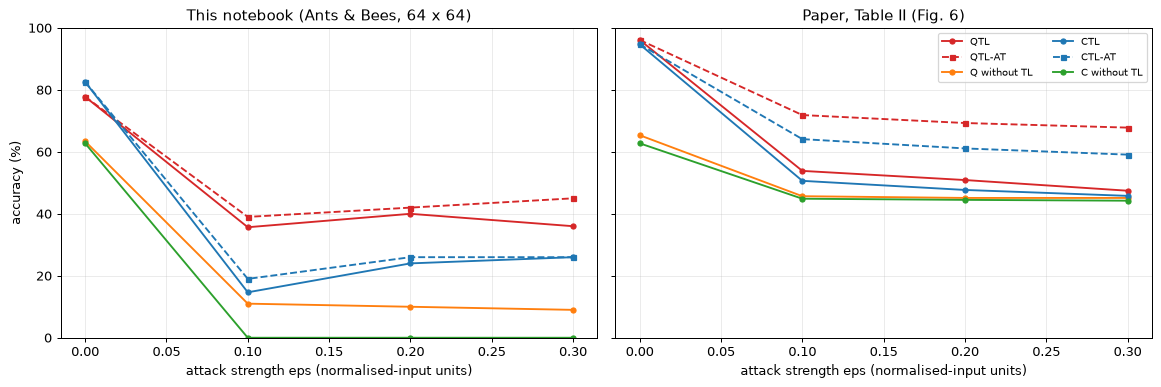

In [16]:
# ---------------- Fig. 6 re-drawn: accuracy versus attack strength on Ants & Bees ----------------
SER = [("QTL", "Quantum TL", False, "tab:red", "-o"), ("QTL-AT", "Quantum TL", True, "tab:red", "--s"),
       ("Q without TL", "Quantum w/o TL", False, "tab:orange", "-o"),
       ("CTL", "Classical TL", False, "tab:blue", "-o"), ("CTL-AT", "Classical TL", True, "tab:blue", "--s"),
       ("C without TL", "Classical w/o TL", False, "tab:green", "-o")]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for name, meth, at, col, sty in SER:
    xs, ys = ([0.0], [val("ants_bees", meth, 0.0, "none", 0.0)[0]])
    if at:                                           # the model adversarially trained at strength e, attacked at e
        xs += [e for e in EPS_ANTS if val("ants_bees", meth, e, "fgsm", e)[2]]
        ys += [val("ants_bees", meth, e, "fgsm", e)[0] for e in EPS_ANTS if val("ants_bees", meth, e, "fgsm", e)[2]]
    else:
        ev = [e for e in eval_grid("ants_bees") if val("ants_bees", meth, 0.0, "fgsm", e)[2]]
        xs += ev; ys += [val("ants_bees", meth, 0.0, "fgsm", e)[0] for e in ev]
    ax[0].plot(xs, ys, sty, color=col, label=name, ms=4)
    # paper: clean accuracy at 0, then Table II
    px = [0.0] + EPS_ANTS
    py = [PAPER_T1["ants_bees"][meth]] + [PAPER_T2[meth][e][2 if at else 0] for e in EPS_ANTS]
    ax[1].plot(px, py, sty, color=col, label=name, ms=4)
ax[0].set_title("This notebook (Ants & Bees, 64 x 64)"); ax[1].set_title("Paper, Table II (Fig. 6)")
for a in ax:
    a.set_xlabel("attack strength eps (normalised-input units)"); a.set_ylim(0, 100)
ax[0].set_ylabel("accuracy (%)"); ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

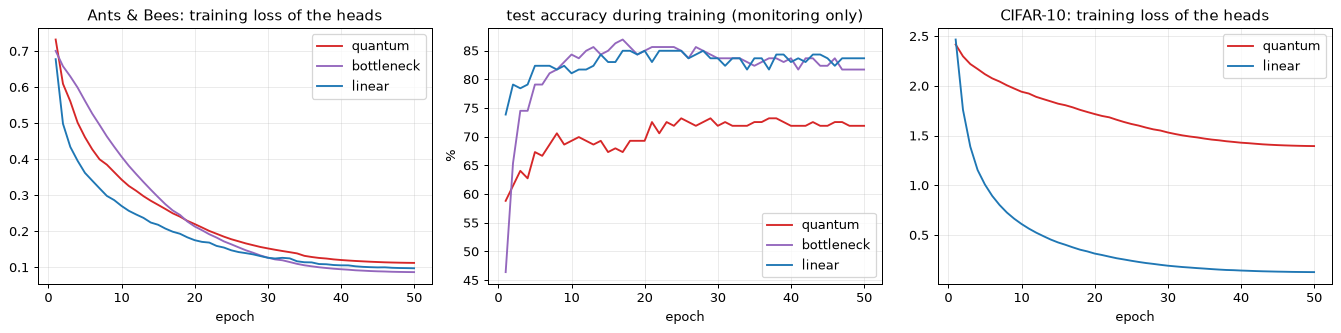

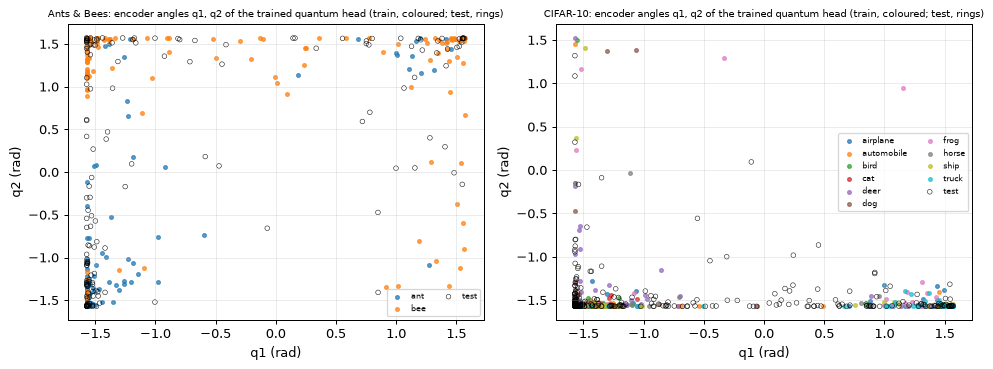

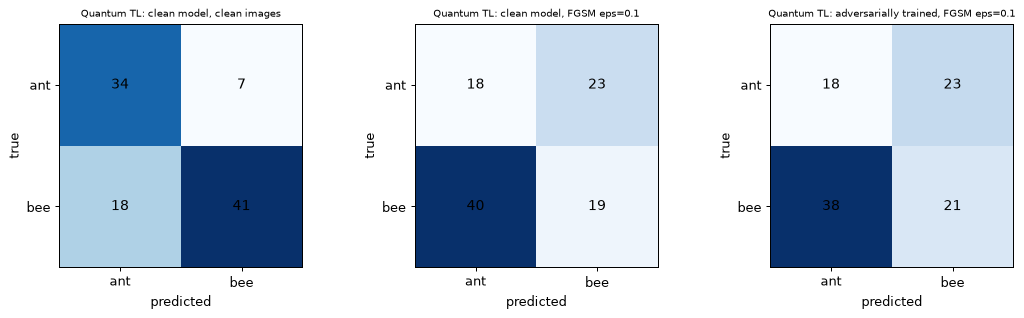

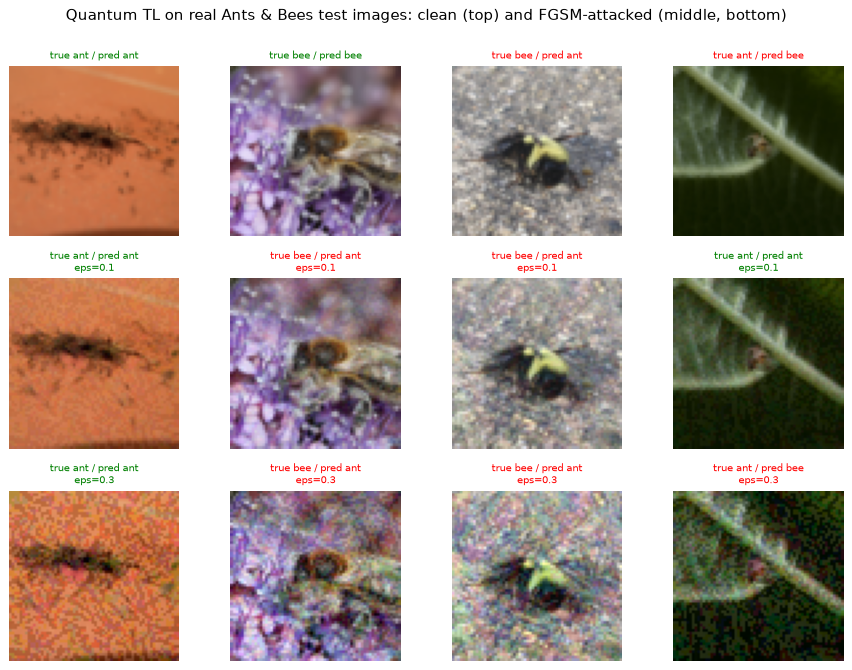

In [17]:
# ---------------- training curves, encoder angles, confusion matrices, adversarial examples ----------------
s0 = SEEDS[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for kind, col in (("quantum", "tab:red"), ("bottleneck", "tab:purple"), ("linear", "tab:blue")):
    h = pd.DataFrame(HIST[("ants_bees", kind, s0)])
    ax[0].plot(h.epoch, h.loss, color=col, label=kind); ax[1].plot(h.epoch, h.test_acc, color=col, label=kind)
ax[0].set_title("Ants & Bees: training loss of the heads"); ax[1].set_title("test accuracy during training (monitoring only)")
ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[0].legend(); ax[1].legend()
d = DATA["cifar10"]; h = pd.DataFrame(HIST[("cifar10", "quantum", s0)]); h2 = pd.DataFrame(HIST[("cifar10", "linear", s0)])
ax[2].plot(h.epoch, h.loss, color="tab:red", label="quantum"); ax[2].plot(h2.epoch, h2.loss, color="tab:blue", label="linear")
ax[2].set_title("CIFAR-10: training loss of the heads"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

# the angles the circuit really receives: first two encoder angles of the trained quantum head, coloured by the true class
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, key in zip(ax, ("ants_bees", "cifar10")):
    dd = DATA[key]; hq = STORE[(key, "tl", "quantum", s0, 0.0)]
    with torch.no_grad():
        Atr, Ate = hq.angles(dd["Ftr"]).numpy(), hq.angles(dd["Fte"]).numpy()
    for c in range(dd["n_cls"]):
        m = dd["ytr"] == c
        a.scatter(Atr[m, 0], Atr[m, 1], s=9, color=plt.cm.tab10(c), alpha=0.7, label=dd["classes"][c])
    a.scatter(Ate[:, 0], Ate[:, 1], s=14, facecolors="none", edgecolors="k", linewidths=0.4, label="test")
    a.set_title(f"{dd['title']}: encoder angles q1, q2 of the trained quantum head (train, coloured; test, rings)", fontsize=8)
    a.set_xlabel("q1 (rad)"); a.set_ylabel("q2 (rad)"); a.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

# confusion matrices of the quantum TL model on Ants & Bees: clean, under FGSM, adversarially trained under FGSM
from sklearn.metrics import confusion_matrix
dd = DATA["ants_bees"]; e = EPS_ANTS[0]
Xev, yev = dd["Xte"][dd["eval_idx"]], dd["yte_t"][dd["eval_idx"]]
def predictions(net, eps):
    net.eval(); out = []
    for s in range(0, len(yev), 50):
        xn, yy = to_norm(Xev[s:s + 50]), yev[s:s + 50]
        if eps > 0:
            xn = fgsm(net, xn, yy, eps)
        with torch.no_grad():
            out.append(net(xn).argmax(1))
    return torch.cat(out).numpy()
nets = [("clean model, clean images", STORE[("ants_bees", "tl", "quantum", s0, 0.0)], 0.0),
        (f"clean model, FGSM eps={e}", STORE[("ants_bees", "tl", "quantum", s0, 0.0)], e),
        (f"adversarially trained, FGSM eps={e}", STORE[("ants_bees", "tl", "quantum", s0, e)], e)]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, (ttl, hd, ee) in zip(ax, nets):
    cm_ = confusion_matrix(yev.numpy(), predictions(FullNet(bb_tl, hd), ee), labels=[0, 1])
    a.imshow(cm_, cmap="Blues"); a.set_title(f"Quantum TL: {ttl}", fontsize=8)
    a.set_xticks([0, 1]); a.set_xticklabels(dd["classes"]); a.set_yticks([0, 1]); a.set_yticklabels(dd["classes"])
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, int(cm_[i, j]), ha="center", va="center", color="black", fontsize=11)
plt.tight_layout(); plt.show()

# a few real test images, their FGSM versions and what the quantum TL model says
hq = STORE[("ants_bees", "tl", "quantum", s0, 0.0)]; net = FullNet(bb_tl, hq); net.eval()
sel = np.arange(4)
xn, yy = to_norm(Xev[sel]), yev[sel]
fig, ax = plt.subplots(3, 4, figsize=(10, 7.4))
for r_, ee in enumerate((0.0, EPS_ANTS[0], EPS_ANTS[-1])):
    xa = fgsm(net, xn, yy, ee) if ee > 0 else xn
    with torch.no_grad():
        pr = net(xa).argmax(1)
    for c_ in range(4):
        img = (xa[c_:c_ + 1] * STD + MEAN).clamp(0, 1)[0].permute(1, 2, 0).numpy()
        ax[r_, c_].imshow(img); ax[r_, c_].axis("off")
        ax[r_, c_].set_title(f"true {dd['classes'][int(yy[c_])]} / pred {dd['classes'][int(pr[c_])]}" + ("" if ee == 0 else f"\neps={ee}"), fontsize=8,
                             color="green" if int(pr[c_]) == int(yy[c_]) else "red")
plt.suptitle("Quantum TL on real Ants & Bees test images: clean (top) and FGSM-attacked (middle, bottom)", y=1.0)
plt.tight_layout(); plt.show()

## 8. Side by side with the paper, claim by claim

Verdict rules: a number is **reproduced** if it lies within 2 accuracy points of the paper's value, **exceeded** / **not reached** otherwise (with the gap). For comparisons ("quantum is better than classical by x points") the verdict looks first at the *direction* and then at the size of the gap. "Cannot be checked" means the measurement was not run (for example, in `FAST_MODE`) or the paper's data is not available. With a test set of 153 images one image is 0.65 points, and the standard error of an accuracy near 95 % is about 1.8 points, so differences of 1-2 points between two methods are within sampling noise.

In [18]:
def V(paper, ours, tol=2.0):
    if ours is None or np.isnan(ours):
        return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

def VG(paper_gap, our_gap, tol=2.0):
    """verdict for a claim about a difference between two methods"""
    if our_gap is None or np.isnan(our_gap):
        return "cannot be checked"
    if our_gap <= 0:
        return f"not reproduced (gap {our_gap:+.1f}, paper {paper_gap:+.1f})"
    if abs(our_gap - paper_gap) <= tol:
        return "reproduced"
    return f"direction reproduced, larger ({our_gap:+.1f} vs paper {paper_gap:+.1f})" if our_gap > paper_gap else f"direction reproduced, smaller ({our_gap:+.1f} vs paper {paper_gap:+.1f})"

claims = []
def claim(text, paper, ours, verdict):
    claims.append({"claim": text, "paper": paper if isinstance(paper, str) else round(paper, 2),
                   "notebook": ours if isinstance(ours, str) else (np.nan if ours is None or np.isnan(ours) else round(ours, 1)), "verdict": verdict})

m1 = lambda key, meth, te, att, ee: val(key, meth, te, att, ee)[0]
# Table I numbers
for key in DATA:
    for meth in ["Classical TL", "Quantum TL", "Classical w/o TL", "Quantum w/o TL"]:
        o = m1(key, meth, 0.0, "none", 0.0)
        claim(f"Table I {DATA[key]['title']}: clean accuracy, {meth}", PAPER_T1[key][meth], o, V(PAPER_T1[key][meth], o))
# C1: quantum beats classical TL
for key, pg_ in (("ants_bees", 1.4), ("cifar10", 3.7)):
    g_ = m1(key, "Quantum TL", 0.0, "none", 0.0) - m1(key, "Classical TL", 0.0, "none", 0.0)
    claim(f"{DATA[key]['title']}: QTL - classical TL, clean accuracy (points)", pg_, g_, VG(pg_, g_))
# C2: transfer learning is essential
for key, pq_, pc_ in (("ants_bees", 30.74, 31.95), ("cifar10", 44.1, 19.2)):
    gq = m1(key, "Quantum TL", 0.0, "none", 0.0) - m1(key, "Quantum w/o TL", 0.0, "none", 0.0)
    gc = m1(key, "Classical TL", 0.0, "none", 0.0) - m1(key, "Classical w/o TL", 0.0, "none", 0.0)
    claim(f"{DATA[key]['title']}: quantum TL - quantum w/o TL (points)", pq_, gq, VG(pq_, gq, tol=10.0))
    claim(f"{DATA[key]['title']}: classical TL - classical w/o TL (points)", pc_, gc, VG(pc_, gc, tol=10.0))
# Table II / IV: under attack, adversarial training
for e in EPS_ANTS:
    for meth in ["Classical TL", "Quantum TL"]:
        pa, pc, pat = PAPER_T2[meth][e]
        claim(f"Table II eps={e}: {meth}, accuracy under FGSM", pa, m1("ants_bees", meth, 0.0, "fgsm", e), V(pa, m1("ants_bees", meth, 0.0, "fgsm", e)))
        claim(f"Table II eps={e}: {meth}, adversarially trained model, accuracy under FGSM", pat, m1("ants_bees", meth, e, "fgsm", e),
              V(pat, m1("ants_bees", meth, e, "fgsm", e)))
    pg_ = PAPER_T2["Quantum TL"][e][2] - PAPER_T2["Quantum TL"][e][0]
    g_ = m1("ants_bees", "Quantum TL", e, "fgsm", e) - m1("ants_bees", "Quantum TL", 0.0, "fgsm", e)
    claim(f"Ants & Bees eps={e}: gain of adversarial training for QTL under attack (points)", pg_, g_, VG(pg_, g_, tol=5.0))
    pg_ = PAPER_T2["Quantum TL"][e][2] - PAPER_T2["Classical TL"][e][2]
    g_ = m1("ants_bees", "Quantum TL", e, "fgsm", e) - m1("ants_bees", "Classical TL", e, "fgsm", e)
    claim(f"Ants & Bees eps={e}: QTL-AT minus CTL-AT accuracy under attack (points)", pg_, g_, VG(pg_, g_, tol=5.0))
for e in EPS_C10:
    for meth in ["Classical TL", "Quantum TL"]:
        pa, pat = PAPER_T4[meth][e]
        claim(f"Table IV eps={e}: {meth}, accuracy under FGSM", pa, m1("cifar10", meth, 0.0, "fgsm", e), V(pa, m1("cifar10", meth, 0.0, "fgsm", e), tol=5.0))
        claim(f"Table IV eps={e}: {meth}, after adversarial training", pat, m1("cifar10", meth, e, "fgsm", e), V(pat, m1("cifar10", meth, e, "fgsm", e), tol=5.0))
claim("Table III (Road Sign Detection), all rows", "see paper", "not run", "cannot be checked (dataset not available)")
# claim: an undefended model loses a large part of its accuracy under attack (QTL, smallest eps)
e = EPS_ANTS[0]; drop = m1("ants_bees", "Quantum TL", 0.0, "none", 0.0) - m1("ants_bees", "Quantum TL", 0.0, "fgsm", e)
claim(f"Ants & Bees: accuracy drop of undefended QTL under FGSM eps={e} (points)", 42.25, drop, VG(42.25, drop, tol=10.0))
# claim: AT improves accuracy under attack for every model that was adversarially trained
imp = [(meth, e_) for meth in ["Classical TL", "Quantum TL"] for e_ in EPS_ANTS
       if m1("ants_bees", meth, e_, "fgsm", e_) > m1("ants_bees", meth, 0.0, "fgsm", e_)]
claim("Ants & Bees: adversarial training improves accuracy under FGSM (TL models, count of 6 cases)", "6 of 6", f"{len(imp)} of 6", "reproduced" if len(imp) == 6 else "not reproduced")

CLAIMS = pd.DataFrame(claims)
pd.set_option("display.width", 250, "display.max_colwidth", 95)
print(CLAIMS.to_string(index=False))
vc = CLAIMS.verdict.str.split(" ").str[0].value_counts()
print("\nverdict summary:", vc.to_dict())

                                                                                       claim     paper notebook                                              verdict
                                           Table I Ants & Bees: clean accuracy, Classical TL      94.7     82.6                                  not reached (-12.1)
                                             Table I Ants & Bees: clean accuracy, Quantum TL      96.1     77.8                                  not reached (-18.3)
                                       Table I Ants & Bees: clean accuracy, Classical w/o TL     62.75     62.7                                           reproduced
                                         Table I Ants & Bees: clean accuracy, Quantum w/o TL     65.36     63.4                                           reproduced
                                              Table I CIFAR-10: clean accuracy, Classical TL      92.1     61.6                                  not reached (-30.5)
          

### Reading the numbers of this executed run (`FAST_MODE = True`)

These statements describe the outputs above (one run, `SEEDS = [42, 43, 44]` for the clean TL models, 100 attacked test images, 64 x 64 pixels, short adversarial-training budgets); they are not a re-measurement of the paper's full-resolution setting.

* **Clean accuracy, Ants & Bees.** Classical TL 82.6 +/- 0.8 %, quantum TL 77.8 +/- 5.8 %, classical head with the same 6-unit bottleneck 82.1 +/- 2.2 % (paper 94.7 / 96.1 %). The paper's ranking "quantum TL beats classical TL" is **not reproduced** (here -4.8 points, inside one standard deviation of the quantum seeds), and the same holds on CIFAR-10 (quantum 30.8 %, bottleneck 45.9 %, classical 61.6 %, with 400 training images and ten classes). A look at the trained encoder angles (scatter above) shows why: with raw, un-normalised ResNet features the `tanh` of the 512 -> 6 layer saturates at +-pi/2, so most angles the circuit receives sit at the ends of the allowed range. This is a consequence of the paper's recipe as written, not of a bug: the twin-versus-QNode assertions pass.
* **Transfer learning.** The networks trained from random weights reach 62.7 % (classical) and 63.4 % (quantum) on Ants & Bees, within 2 points of the paper's 62.75 % and 65.36 %. Transfer learning helps (+19.8 points classical, +14.4 quantum, paper +32.0 / +30.7): the direction is reproduced, the size is smaller because the frozen features at 64 x 64 pixels are weaker. The CIFAR-10 no-TL networks had only 2 epochs and are far below the paper.
* **Attack.** An undefended model loses 42 points of accuracy under FGSM eps = 0.1 for quantum TL (paper: 42.25), which is reproduced, but the absolute accuracies are well **below** the paper's near-50 % values (classical TL 14.7 %, quantum TL 35.7 % at eps = 0.1). On a balanced two-class problem an accuracy below 50 % is what a working untargeted white-box attack produces; the paper's values at chance level suggest a weaker attack or a different `eps` unit. The ordering "quantum TL keeps more accuracy than classical TL under attack" holds at all three strengths here (35.7 vs 14.7, 40.0 vs 24.0, 36.0 vs 26.0), but the quantum model also starts from a lower clean accuracy and the test uses 100 images and one attack seed, so this is weak evidence.
* **Adversarial training.** With only 2 epochs of warm-started FGSM training, accuracy under attack rises by 3.3, 2.0 and 9.0 points for quantum TL (paper +18 to +20) and by 4.3, 2.0 and 0.0 points for classical TL; on CIFAR-10 (one epoch) it does not help. The paper's large gains are **not reached** with this budget. PGD at eps = 0.1 (extra table) leaves the adversarially trained models at 25 % (quantum) and 5 % (classical), i.e. FGSM-based training transfers little robustness to a stronger attack, as the critical notes below anticipate.
* **Not run.** `FAST_MODE = False` (3 seeds are already used here; full sizes, 4 + 2 adversarial-training epochs, 15 + 4 epochs without TL, all attack strengths for every model) would take several hours on a CPU and was not executed. Table III (Road Sign Detection) cannot be checked.

## 9. Reading the paper critically

* **Sampling noise.** The Ants & Bees test set has 153 images: one image is 0.65 percentage points and the binomial standard error of an accuracy around 95 % is about 1.8 points. The claimed 1.4-point advantage of quantum over classical TL is smaller than one standard error, and the paper reports a single run without seeds. The CIFAR-10 gap (3.7 points) is larger, but its size depends on which 10,000 images and which unreported augmentation were used.
* **What is being compared.** The quantum head has a 512 -> 6 encoder plus 108 circuit weights plus a 6 -> classes layer; the "classical TL" baseline is most likely a single linear layer. A fairer control is a classical head with the *same* 6-unit bottleneck, which this notebook adds. Any advantage of the circuit over that control is the quantum contribution; an advantage over the plain linear layer is mostly the extra non-linear layers.
* **"Robustness".** In the paper all undefended models fall to about chance level (50 % for two balanced classes) under FGSM, quantum or not, which it concedes ("as vulnerable as classical TL"); here the white-box attack pushes them below chance. The claim that QTL is "adversarially robust ... and outperforms classical methods" rests on accuracies that differ by a few points at near-chance level, and on adversarial training against **the same** FGSM attack used for testing. FGSM-trained models are known to be vulnerable to stronger attacks (gradient masking, catastrophic overfitting); the PGD rows above are the check the paper does not contain.
* **Attack strength units.** The paper never says whether `eps` is in pixel units or in normalised units. In 0-1 pixel units eps = 1.0 (Tables III and IV) would replace the whole picture and accuracy could not stay near 60 % (Road Sign); in normalised units it is a strong but meaningful perturbation. The accuracy floor of exactly 50.0 % on ten-class CIFAR-10 (Table IV) is also hard to reconcile with ten balanced classes (chance is 10 %): either a binary subset was used or the table reports something else. This notebook runs the ten-class problem as described in the text.
* **Without transfer learning.** Section III-C says the ResNet-18 is "pre-trained" and also "fine-tuned from scratch". The numbers (62-65 % on Ants & Bees) match a network trained from random weights on 245 images, which is the interpretation used here. That comparison measures the value of ImageNet, not of the quantum circuit.
* **Third dataset.** Road Sign Detection is an object-detection set; how its images were turned into one label each, and which 80/20 split was used, is not stated, and the images were not found on any public mirror in that form. Table III therefore cannot be checked.
* **Quantum aspects.** The circuit is simulated exactly; no noise, no shots and no hardware are involved, so the paper's motivation (few noisy qubits) is not tested. The CNOT wiring, rotation order and the exact observables are not printed in the paper.

## 10. Exercises

1. **Seeds.** Set `SEEDS = [42, 43, 44, 45, 46]` and `FAST_MODE = True`: is the quantum-minus-classical difference on Ants & Bees larger than the seed-to-seed standard deviation?
2. **Control.** Compare the "6-unit bottleneck" classical head with the quantum head in `T1`. Does the circuit add anything beyond the narrow bottleneck?
3. **Depth.** Change `N_LAYERS` to 1, 2 and 6. Does the clean accuracy or the accuracy under FGSM change? (The circuit drawing and the twin assertion update automatically.)
4. **Attack strength.** Add `0.02` and `0.05` to `EPS_ANTS`. At which strength does the undefended TL model start to fail, and does adversarial training at 0.1 still help at 0.02?
5. **Stronger attack.** Evaluate the FGSM-trained models with `PGD_STEPS = 20` and a smaller step. How much of the adversarial-training gain survives?